# Deteção de tendência da pressão arterial · regressão quantílica sobre o Δ

Este notebook reúne o código do **modelo de tendência adotado na tese**, um regressor quantílico (XGBoost) que, a partir só do PPG, prevê a variação da pressão sistólica nos **últimos 5 minutos**, `Δ = PAS(t) − PAS(t − 5 min)`. Há dois detetores, um de descida e um de subida de pelo menos 15 mmHg.

O caminho vai das janelas de sinal do MIMIC ao modelo instalado no servidor:

1. extração das características de cada janela de 15 s;
2. conjunto de dados causal (blocos de 15 s, sessões, normalização pela janela de calibração, divisão por doente);
3. grade de tempo, características temporais e alvos;
4. hiperparâmetros;
5. modelo final e discriminação no conjunto de teste;
6. validação cruzada no conjunto de desenvolvimento;
7. alarmes, episódios e custo;
8. ponto de operação conjunto das duas direções;
9. métricas por episódio e valor preditivo positivo;
10. exportação do modelo e comparação com o que está no servidor;
11. o que fica fora deste notebook.

**Janela e características.** A janela de 5 minutos é medida no **tempo** e não em número de blocos (cada sessão fica numa grade regular de 15 s e um bloco em falta é uma linha vazia), e o modelo usa **43 características** (19 de base mais 24 de morfologia do pulso). A escolha da janela, do quantil e do conjunto de características foi feita só com o conjunto de desenvolvimento.

**Verificação.** Cada passo termina com `confere(...)`, que compara o resultado com o valor usado na tese (os ficheiros de `3_tendencia_modelo_final/tendencia_tempo_fixo`). Se algum passo divergir, o notebook para nesse ponto.

**Versões.** Os valores da tese foram obtidos com o XGBoost 3.3.0 e o scikit-learn 1.9.1, e as primeiras verificações do notebook confirmam as versões. Com outras versões os AUC diferem na terceira ou quarta casa decimal (o XGBoost muda o modelo, o scikit-learn muda a repartição dos doentes pelas dobras) e as verificações seguintes falham.

**Tempo.** Com os interruptores por omissão corre em cerca de uma a duas horas. Os dois passos mais lentos estão desligados e só correm se se mudarem os interruptores da célula seguinte. A extração completa do MIMIC demora várias horas, e a pesquisa de hiperparâmetros (20 tentativas por direção) também.

Os gráficos têm o texto em inglês, como as figuras da tese.

In [1]:
import hashlib, io, json, os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import xgboost as xgb
from xgboost import XGBRegressor
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import GroupKFold

# ── interruptores ────────────────────────────────────────────────────────────────────────────────
REFAZER_EXTRACAO = False   # extração de todas as janelas do MIMIC em bruto (várias horas, 16 processos)
REFAZER_DATASET = True     # reconstrói o conjunto de dados a partir das janelas e confirma que é igual ao guardado
REFAZER_OPTUNA = False     # nova pesquisa de hiperparâmetros (20 tentativas por direção)

# ── caminhos ─────────────────────────────────────────────────────────────────────────────────────
MIMIC = "/media/filipe/Dados/MIMIC_DATASET_CONSOLIDADO"            # registos do MIMIC-III/IV e lista de segmentos
FEATURES = "/media/filipe/Dados/Features_morfologia"               # janelas extraídas (passo 1), com as características novas
TESE = "/home/filipe/Desktop/Tese/algoritmo-ml"
IDS_TESTE = f"{TESE}/RESULTADOS_RELATORIO/codigo_dependencias/particao_sujeitos/pacientes_holdout.txt"  # o teste do absoluto
REF = f"{TESE}/Tentativa_22_10/tendencia_tempo_fixo"               # resultados usados na tese (hiperparâmetros, ponto de operação)
DADOS = f"{REF}/dados"                                            # a tabela única da tendência (passo 2), a que a cadeia lê
SERVIDOR = "/home/filipe/Desktop/Tese/server/modelo_tendencia_ppg_quant.joblib"
SAIDA = os.path.abspath("saidas/03_regressao_quantilica")
os.makedirs(SAIDA, exist_ok=True)

# ── constantes do problema ───────────────────────────────────────────────────────────────────────
BLOCO_SEG = 15                 # 3 janelas de 15 s com passo de 5 s formam um bloco de 15 s
D, W_MIN = 15, 5               # evento: variação da pressão sistólica de pelo menos 15 mmHg em 5 minutos
N_CALIB = 10                   # blocos da janela de calibração (2,5 minutos)
DIRS = ("descida", "subida")
Q = {"descida": 0.10, "subida": 0.90}      # quantil do Δ previsto em cada direção
SINAL = {"descida": -1.0, "subida": 1.0}   # score = queda prevista (descida) ou subida prevista (subida), em mmHg
GAP_MERGE = int(1 * 60 / BLOCO_SEG)        # alarmes ou episódios separados por até 1 minuto contam como um só
PRE_CREDITO = int(2 * 60 / BLOCO_SEG)      # um alarme até 2 minutos antes do episódio conta como deteção
DUTY_MAX = 0.30                            # ciclo de serviço máximo admissível (fração do tempo em alarme)

FEAT_BASE = ['hr_mean_z', 'hr_lag1', 'area_mean_global_z', 'w50_global_z', 'alpha_womersley_global_z',
             'ppg_crest_time_global_z', 'ppg_decay_time_global_z', 'age', 'gender_bin']
SLOPE_COLS = ['hr_mean_z', 'area_mean_global_z', 'alpha_womersley_global_z']
MORF = ['w50_global_z', 'ppg_crest_time_global_z', 'ppg_decay_time_global_z']                # só as variações entram de novo
APG = ['apg_b_a_global_z', 'apg_d_a_global_z']                                                # rácios b/a e d/a da segunda derivada
NOVAS = ['w25_global_z', 'w75_global_z', 'ppg_max_slope_norm_global_z', 'reflection_index_global_z']

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.linestyle": ":", "grid.alpha": 0.5})
VERM, AZUL, CINZA = "#c0392b", "#1f5fa8", "#888888"

VERIFICACOES = []
def confere(nome, obtido, referencia, tol=0.0):
    # compara com o valor da tese; números com tolerância absoluta, o resto por igualdade
    if isinstance(referencia, (int, float, np.floating, np.integer)) and not isinstance(referencia, bool):
        ok = abs(float(obtido) - float(referencia)) <= tol
    else:
        ok = obtido == referencia
    VERIFICACOES.append((nome, obtido, referencia, ok))
    assert ok, f"{nome}: obtido {obtido}, na tese {referencia}"
    mostra = f"{len(obtido)} elementos, iguais" if isinstance(obtido, (list, tuple)) and len(obtido) > 12 else obtido
    print(f"  ok  {nome}: {mostra}")


# Os resultados da tese foram obtidos com o XGBoost 3.3.0 e o scikit-learn 1.9.1. Noutra versão do XGBoost o AUC muda na quarta
# casa decimal (medido: com a 3.2.0 o teste da descida dá 0,8002 em vez de 0,7997), e o GroupKFold do scikit-learn 1.8 reparte os
# doentes pelas dobras de outra forma (a validação cruzada da descida dá 0,8115 em vez de 0,8128). Os passos seguintes deixam de bater.
import sklearn
confere("versão do XGBoost (a dos resultados da tese)", xgb.__version__, "3.3.0")
confere("versão do scikit-learn (a dos resultados da tese)", sklearn.__version__, "1.9.1")

  ok  versão do XGBoost (a dos resultados da tese): 3.3.0
  ok  versão do scikit-learn (a dos resultados da tese): 1.9.1


## 1. Extração das características de cada janela de PPG

Cada registo do MIMIC é percorrido em janelas de 15 s com passo de 5 s. Em cada janela:

* o PPG passa por um filtro passa-baixo de 8 Hz e a orientação é corrigida (pico sistólico como máximo);
* os batimentos são segmentados **só pelos picos do PPG**, sem ECG;
* a janela é rejeitada se não passar os portões de qualidade (número de batimentos, frequência cardíaca entre 45 e 140, regularidade do ritmo, excursão anómala, dispersão do tempo de subida);
* por batimento calculam-se a frequência cardíaca, o tempo de subida e de descida, a área e a largura a meia altura do pulso, o índice de Womersley e as características da segunda derivada (APG), e a janela fica com a média dos batimentos aceites;
* a extração calcula ainda as **características de morfologia**, as larguras do pulso a 25 % e a 75 % da altura (`w25`, `w75`), a inclinação máxima da subida normalizada pela amplitude e pela duração do pulso, e o índice de reflexão (relação entre o entalhe dicrótico e o pico sistólico);
* o alvo é a pressão sistólica média da janela, tirada do sinal de pressão arterial invasiva, que também tem um portão de qualidade.

O código desta secção é o do script `3_tendencia_modelo_final/extracao_morfologia/09b_extrair_features_ppg_morfologia.py`, copiado sem alterações. A extração completa demora várias horas. Por omissão, este notebook corre-a num só registo e confirma que as janelas obtidas são iguais às guardadas.

In [2]:
import wfdb
from scipy.signal import find_peaks, butter, filtfilt, savgol_filter
from scipy.integrate import simpson
from scipy.stats import skew

WINDOW_SIZE_SEC = 15
STRIDE_SEC = 5

RHO_SANGUE = 1060

# Portões de qualidade — os limiares que têm equivalente direto no original
# mantêm o mesmo valor, para a comparação não misturar "mudei a segmentação"
# com "mudei o critério de aceitação".
MIN_BATIMENTOS      = 8       # era len(r_peaks) < 8
MIN_BATIMENTOS_KEPT = 6       # era len(kept) < 6
CV_RITMO_MAX        = 0.25    # era cv_rr > 0.25 (irregularidade do ritmo)
DISPERSAO_MAX       = 0.05    # limite de std(crest_time)
HR_MIN, HR_MAX      = 45, 140  # era o mesmo intervalo no filtro de PAT do original
CREST_MIN, CREST_MAX = 0.05, 0.40   # crest time fisiologicamente plausível (s)


def butter_lowpass_filter(data, cutoff, fs, order=4):
    b, a = butter(order, cutoff / (0.5 * fs), btype='low', analog=False)
    return filtfilt(b, a, data)


def extrair_targets_abp_robusto(win_abp, fs):
    """Idêntico ao original — é a etiqueta, não pode mudar."""
    sbp_idxs, _ = find_peaks(win_abp, distance=int(fs * 0.4), height=np.percentile(win_abp, 50))
    dbp_idxs, _ = find_peaks(-win_abp, distance=int(fs * 0.4))
    if len(sbp_idxs) < 3 or len(dbp_idxs) < 3:
        return None, None, None, None
    sbp_vals = win_abp[sbp_idxs]
    sbp_mean = float(np.mean(sbp_vals))
    sbp_std = float(np.std(sbp_vals))
    dbp_mean = float(np.mean(win_abp[dbp_idxs]))
    return sbp_mean, dbp_mean, sbp_std, sbp_mean - dbp_mean


def extrair_apg_features(pulso, fs):
    """Ondas a,b,c,d,e da 2ª derivada (APG) de UM pulso PPG e os rácios b/a, c/a,
    d/a + índice de envelhecimento (b-c-d-e)/a. Método Elgendi/Takazawa: NÃO precisa
    do pé nem do entalhe dicrótico (mais robusto que crest/decay times). None se não
    fiável.

    Cópia literal da função do 09_extrair_features_ppg_apg.py (código próprio em scipy, método
    Takazawa/Elgendi, sem NeuroKit) — não alterar, senão deixa de ser comparável.
    """
    if len(pulso) < int(0.3 * fs):
        return None
    win_sg = max(5, int(0.05 * fs) | 1)   # ímpar, ~50ms
    if len(pulso) <= win_sg:
        return None
    suave = savgol_filter(pulso, win_sg, 3)
    apg = np.gradient(np.gradient(suave))

    metade = len(apg) // 2
    picos_pos, _ = find_peaks(apg[:metade])
    if len(picos_pos) == 0:
        return None
    a_idx = picos_pos[int(np.argmax(apg[picos_pos]))]
    a_val = apg[a_idx]
    if a_val <= 0:
        return None

    resto_neg, _ = find_peaks(-apg[a_idx:])
    if len(resto_neg) == 0:
        return None
    b_idx = a_idx + resto_neg[int(np.argmax(-apg[a_idx + resto_neg]))]
    b_val = apg[b_idx]

    lim_dic = min(len(apg), b_idx + int(0.45 * fs))

    def _prox_extremo(sig, start, fim):
        if start >= fim:
            return None
        p, _ = find_peaks(sig[start:fim])
        return start + p[0] if len(p) > 0 else None

    c_idx = _prox_extremo(apg, b_idx + 1, lim_dic)
    c_val = apg[c_idx] if c_idx is not None else np.nan
    d_idx = _prox_extremo(-apg, (c_idx + 1) if c_idx is not None else b_idx + 1, lim_dic)
    d_val = apg[d_idx] if d_idx is not None else np.nan
    e_idx = _prox_extremo(apg, (d_idx + 1) if d_idx is not None else b_idx + 1, lim_dic)
    e_val = apg[e_idx] if e_idx is not None else np.nan

    c0 = 0.0 if np.isnan(c_val) else c_val
    d0 = 0.0 if np.isnan(d_val) else d_val
    e0 = 0.0 if np.isnan(e_val) else e_val
    return {
        'apg_b_a': b_val / a_val,
        'apg_c_a': (c_val / a_val) if not np.isnan(c_val) else np.nan,
        'apg_d_a': (d_val / a_val) if not np.isnan(d_val) else np.nan,
        'apg_aging': (b_val - c0 - d0 - e0) / a_val,
    }


def largura_a(norm_p, fs, frac):
    """Largura (s) do pulso a `frac` da amplitude, como o w50: do primeiro ao último ponto >= frac. Devolve (largura, truncada),
    em que truncada = o último ponto acima do limiar é o último da janela (o pulso não desceu abaixo do limiar a tempo)."""
    idx = np.where(norm_p >= frac)[0]
    if len(idx) <= 1:
        return None, False
    return round(float((idx[-1] - idx[0]) / fs), 4), bool(idx[-1] >= len(norm_p) - 1)


def indice_reflexao(win, pk, vly, pe, limite, ac, fs):
    """(pico diastólico - pé) / (pico sistólico - pé). O pico diastólico é o máximo local depois do entalhe `pe` (fim do pulso do
    próprio pipeline) até 0,35 s depois ou ao pico seguinte, o que vier primeiro, com proeminência de pelo menos 2 % da amplitude.
    None se não houver pico distinto (frequente: a onda refletida pode ficar fundida na descida)."""
    if pe is None:
        return None
    fim = min(pe + int(0.35 * fs), limite, len(win))
    if fim - pe < 5:
        return None
    seg = win[pe:fim]
    p, props = find_peaks(seg, prominence=0.02 * ac)
    if len(p) == 0:
        return None
    dp = pe + int(p[int(np.argmax(props['prominences']))])
    ri = (float(win[dp]) - float(win[vly])) / ac
    return round(ri, 4) if 0.0 < ri < 1.0 else None


def corrigir_orientacao(win_ppg):
    """Repõe a convenção do PLETH do MIMIC (pico sistólico = MÁXIMO).

    No MIMIC é sempre um no-op (o PLETH já vem nesta convenção), mas TEM de existir
    aqui para o código de treino e o de produção serem o mesmo: o MAX30102 da
    bancada devolve intensidade de luz recebida e sai com o pulso invertido
    (skew(diff) negativo). Ver extracao_ppg_classificador.py no servidor.
    """
    return -win_ppg if skew(np.diff(win_ppg)) < 0 else win_ppg


def processar_janela_so_ppg(win_ppg, fs):
    """Segmenta batimentos e extrai features usando APENAS o PPG.

    Devolve um dict de features, ou None se a janela não passar os portões.
    """
    win_ppg = corrigir_orientacao(win_ppg)
    win = win_ppg - np.min(win_ppg) + 0.01     # positividade para alpha (não move índices)
    amplitude_janela = float(np.max(win) - np.min(win))
    if amplitude_janela <= 0:
        return None

    # ── 1. Picos sistólicos, diretamente no PPG ──────────────────────────────
    # Mesmos parâmetros que o original usava para `ppg_peaks_all` (distância
    # mínima de 300 ms afasta o entalhe dicrótico; proeminência de 15% da
    # amplitude da janela evita marcar ondulação de linha de base).
    prom_min = amplitude_janela * 0.15
    picos, _ = find_peaks(win, distance=int(fs * 0.30), prominence=prom_min)
    if len(picos) < MIN_BATIMENTOS:
        return None

    # ── 2. Portões de qualidade (equivalentes de PPG aos do ECG) ─────────────
    # Ritmo: o original rejeitava por CV do RR; aqui é o CV do intervalo
    # pico-a-pico do PPG, que mede exatamente a mesma coisa (regularidade do
    # ciclo cardíaco) sem precisar do ECG.
    pp = np.diff(picos) / fs
    if len(pp) < 2:
        return None
    cv_ritmo = float(np.std(pp) / (np.mean(pp) + 1e-9))
    hr_mediana = 60.0 / (float(np.median(pp)) + 1e-9)
    if not (HR_MIN <= hr_mediana <= HR_MAX):
        return None
    if cv_ritmo > CV_RITMO_MAX:
        return None

    # Excursão anómala (artefacto de movimento): o original comparava o máximo
    # absoluto do ECG com 4x a amplitude típica do R. Aqui compara-se o desvio
    # face à mediana com 4x a amplitude pulsátil típica.
    amp_pulsatil = float(np.median([win[p] for p in picos])) - float(np.median(win))
    if amp_pulsatil <= 0:
        return None
    if float(np.max(np.abs(win - np.median(win)))) > 4 * amp_pulsatil:
        return None

    # ── 3. Features por batimento ────────────────────────────────────────────
    batimentos = []
    n = len(picos)
    for i in range(n):
        pk = int(picos[i])
        pk_next = int(picos[i + 1]) if i + 1 < n else None
        pk_prev = int(picos[i - 1]) if i > 0 else None

        # HR do intervalo pico-a-pico do PPG (substitui o R-R)
        hr = round((60 * fs) / (pk_next - pk), 2) if pk_next is not None else None

        # Vale/pé: mínimo antes do pico, limitado pelo pico PPG anterior. Esta
        # lógica já era só-PPG no original (o comentário lá dizia explicitamente
        # "o pé pertence à estrutura do PRÓPRIO PPG").
        ini = max(pk_prev if pk_prev is not None else 0, pk - int(0.4 * fs), 0)
        if ini >= pk:
            continue
        vly = ini + int(np.argmin(win[ini:pk]))

        vly_val = float(win[vly])
        ac = float(win[pk] - win[vly])
        if ac <= 0:
            continue

        crest_time = round((pk - vly) / fs, 4)
        if not (CREST_MIN <= crest_time <= CREST_MAX):
            continue

        omega = (hr / 60.0) if hr is not None else 1.2
        alpha = float(vly_val * np.sqrt((RHO_SANGUE * omega) / (ac + 1e-6)))

        upslope = win[vly:pk + 1]
        deriv = np.diff(upslope) * fs
        max_slope = float(np.max(deriv)) if len(deriv) > 0 else 0.0
        b_coef = 1.0 / (max_slope + 1e-6)
        alpha_b = float(vly_val * np.sqrt((omega * RHO_SANGUE) / (b_coef + 1e-6)))

        # Fim do pulso: 1.º mínimo local depois do pico, limitado pelo pico
        # seguinte. Idêntico ao original (também já não usava o R).
        limite = pk_next if pk_next is not None else min(pk + int(0.9 * fs), len(win))
        pe_ini2 = pk + int(0.04 * fs)
        pe_fim = min(pk + int(0.50 * fs), len(win), limite)
        pe = None
        if pe_ini2 < pe_fim:
            seg = win[pe_ini2:pe_fim]
            mins, _ = find_peaks(-seg, distance=int(fs * 0.05))
            pe = int(pe_ini2 + (mins[0] if len(mins) > 0 else np.argmin(seg)))
            decay_time = round((pe - pk) / fs, 4)
        else:
            decay_time = None

        # Geometria do pulso — janela e normalização idênticas ao original
        p_low = max(0, pk - int(0.1 * fs))
        p_high = min(len(win), pk + int(0.3 * fs))
        pulso = win[p_low:p_high]
        pulse_area = w50 = None
        w25 = w75 = None
        w25_t = w75_t = False
        if len(pulso) > 1 and (np.max(pulso) - np.min(pulso)) > 0.01:
            norm_p = (pulso - np.min(pulso)) / (np.max(pulso) - np.min(pulso))
            pulse_area = round(float(simpson(y=norm_p)), 4)
            idx50 = np.where(norm_p >= 0.5)[0]
            if len(idx50) > 1:
                w50 = round(float((idx50[-1] - idx50[0]) / fs), 4)
            w25, w25_t = largura_a(norm_p, fs, 0.25)
            w75, w75_t = largura_a(norm_p, fs, 0.75)
        ri = indice_reflexao(win, pk, vly, pe, limite, ac, fs)

        # ── APG: 2.ª derivada de um pulso completo a partir do PÉ ──────────
        # O fim do pulso é `vly + 1.1 x` o intervalo pico-a-pico do PPG, a duração
        # de um ciclo medida sem ECG.
        if pk_next is not None:
            fim_pulso = min(vly + int(1.1 * (pk_next - pk)), len(win))
        else:
            fim_pulso = min(vly + int(1.1 * fs * 60.0 / (hr_mediana + 1e-9)), len(win))
        apg = extrair_apg_features(win[vly:fim_pulso], fs)

        batimentos.append({
            'hr': hr, 'crest_time': crest_time, 'decay_time': decay_time,
            'alpha': round(alpha, 4), 'alpha_b': round(alpha_b, 4),
            'pulse_area': pulse_area, 'w50': w50,
            'w25': w25, 'w75': w75, 'w25_trunc': float(w25_t) if w25 is not None else None,
            'w75_trunc': float(w75_t) if w75 is not None else None,
            'ppg_max_slope': round(max_slope, 4), 'ppg_max_slope_norm': round(max_slope / ac, 4),
            'reflection_index': ri,
            'ppg_valley_intensity': round(vly_val, 4),
            'ppg_ac_amplitude': round(ac, 4),
            'apg_b_a':   apg['apg_b_a']   if apg else None,
            'apg_c_a':   apg['apg_c_a']   if apg else None,
            'apg_d_a':   apg['apg_d_a']   if apg else None,
            'apg_aging': apg['apg_aging'] if apg else None,
        })

    # ── 4. Filtro IQR sobre o crest_time ─────────────────────────────────────
    # Substitui o filtro IQR que o original fazia sobre o PAT: remove
    # batimentos cuja morfologia destoa dos restantes da mesma janela.
    crests = np.array([b['crest_time'] for b in batimentos], dtype=float)
    if len(crests) >= 4:
        q1, q3 = np.percentile(crests, [25, 75])
        iqr = (q3 - q1) if (q3 - q1) != 0 else 0.05
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        kept = [b for b in batimentos if lo <= b['crest_time'] <= hi]
    else:
        kept = list(batimentos)

    # Só batimentos com HR fisiológica (o original aplicava o mesmo intervalo)
    kept = [b for b in kept if b['hr'] is None or HR_MIN < b['hr'] < HR_MAX]

    if len(kept) < MIN_BATIMENTOS_KEPT:
        return None

    # ── 5. Portão de dispersão ───────────────────────────────────────────────
    # Análogo direto de `std(PAT) >= 0.05` do original: mesma unidade (s) e
    # mesma ideia — se os fiduciais temporais da janela não são consistentes
    # entre batimentos, a janela não é de confiança.
    if float(np.std([b['crest_time'] for b in kept])) >= DISPERSAO_MAX:
        return None

    def med(key, subset=None):
        # `np.isfinite` e não só `is not None`: extrair_apg_features devolve
        # np.nan (não None) quando não consegue localizar as ondas c/d/e, e um
        # único NaN envenenava a média de toda a janela.
        vals = [b[key] for b in (subset if subset is not None else kept)
                if b.get(key) is not None and np.isfinite(b[key])]
        return round(float(np.mean(vals)), 4) if vals else None

    return {
        'hr_mean': med('hr'),
        'w50': med('w50'),
        'area_mean': med('pulse_area'),
        'ppg_valley_intensity': med('ppg_valley_intensity'),
        'ppg_ac_amplitude': med('ppg_ac_amplitude'),
        'ppg_crest_time': med('crest_time'),
        'ppg_decay_time': med('decay_time'),
        'alpha_womersley': med('alpha'),
        'alpha_womersley_b': med('alpha_b'),
        'apg_b_a': med('apg_b_a'),
        'apg_c_a': med('apg_c_a'),
        'apg_d_a': med('apg_d_a'),
        'apg_aging': med('apg_aging'),
        'w25': med('w25'), 'w75': med('w75'), 'w25_trunc': med('w25_trunc'), 'w75_trunc': med('w75_trunc'),
        'ppg_max_slope': med('ppg_max_slope'), 'ppg_max_slope_norm': med('ppg_max_slope_norm'),
        'reflection_index': med('reflection_index'),
        'n_ri': sum(1 for b in kept if b.get('reflection_index') is not None),
        'n_batimentos': len(kept),
    }


def processar_linha_individual(row):
    s_id = str(row['subject_folder'])
    if len(s_id) == 7:
        dataset_label, canais_abp, canais_ppg = "MIMIC-III", ['ABP', 'ART'], ['PLETH', 'PPG']
    elif len(s_id) == 9:
        dataset_label, canais_abp, canais_ppg = "MIMIC-IV", ['ABP'], ['PLETH']
    else:
        return []

    seg_name = str(row['segment'])
    try:
        seg_order = int(seg_name.split('_')[-1])
    except Exception:
        seg_order = 0

    base_path = row['absolute_path'].replace('.dat', '').replace('.hea', '')
    if not os.path.exists(base_path + '.hea'):
        return []

    try:
        hdr = wfdb.rdheader(base_path)
        fs = hdr.fs
        sig_names = [s.upper() for s in hdr.sig_name]

        # NOTA: não se procura canal de ECG. Um registo sem derivação II mas com
        # PLETH passa a ser utilizável — é precisamente uma das vantagens de um
        # dispositivo sem elétrodos.
        idx_ppg = next((i for i, s in enumerate(sig_names) if any(x in s for x in canais_ppg)), None)
        idx_abp = next((i for i, s in enumerate(sig_names) if any(x in s for x in canais_abp)), None)
        if idx_ppg is None or idx_abp is None:
            return []

        record = wfdb.rdrecord(base_path, channels=[idx_ppg, idx_abp])
        ppg_raw = record.p_signal[:, 0].astype(np.float32)
        abp_raw = record.p_signal[:, 1].astype(np.float32)
        del record

        if np.isnan(ppg_raw).any() or np.isnan(abp_raw).any():
            ppg_raw = pd.Series(ppg_raw).interpolate().ffill().bfill().values
            abp_raw = pd.Series(abp_raw).interpolate().ffill().bfill().values

        ppg_filt = butter_lowpass_filter(ppg_raw, 8, fs)
    except Exception:
        return []

    resultados = []
    samples_per_win = int(WINDOW_SIZE_SEC * fs)
    step_samples = int(STRIDE_SEC * fs)
    num_windows = int((len(ppg_filt) - samples_per_win) / step_samples) + 1

    for w in range(num_windows):
        start = w * step_samples
        end = start + samples_per_win
        win_ppg, win_abp = ppg_filt[start:end], abp_raw[start:end]

        if np.std(win_ppg) < 0.005 or (np.max(win_abp) - np.min(win_abp)) < 15:
            continue

        sbp, dbp, sbp_std, pp = extrair_targets_abp_robusto(win_abp, fs)
        if sbp is None or not (pp > 25 and sbp_std < 12 and 65 < sbp < 195 and 35 < dbp < 115):
            continue

        feats = processar_janela_so_ppg(win_ppg, fs)
        if feats is None:
            continue

        resultados.append({
            'subject_id': s_id, 'segment_name': seg_name, 'segment_order': seg_order,
            'window_idx': w, 'dataset': dataset_label,
            'gender': row['gender'], 'age': row['age'],
            **feats,
            'sbp_target': round(sbp, 2), 'dbp_target': round(dbp, 2),
        })

    return resultados

In [3]:
segmentos = pd.read_csv(f"{MIMIC}/dataset_para_extração_features.csv")
print(f"{len(segmentos)} segmentos do MIMIC na lista")

if REFAZER_EXTRACAO:
    from joblib import Parallel, delayed
    t0 = time.time()
    raw = Parallel(n_jobs=16, backend="multiprocessing", verbose=5, max_nbytes=None)(
        delayed(processar_linha_individual)(row) for _, row in segmentos.iterrows())
    janelas = pd.DataFrame([x for r in raw if r for x in r])
    for g, rot in (('M', 'homens'), ('F', 'mulheres')):
        janelas[janelas.gender == g].to_csv(f"{SAIDA}/features_{rot}_ppg_apg_morf.csv", index=False)
    print(f"{len(janelas)} janelas em {(time.time() - t0) / 3600:.1f} h")
else:
    janelas = pd.concat([pd.read_csv(f"{FEATURES}/features_{rot}_ppg_apg_morf.csv") for rot in ("homens", "mulheres")],
                        ignore_index=True)
    print(f"janelas guardadas: {len(janelas)} | {janelas.subject_id.nunique()} doentes")

    # demonstração: o primeiro segmento da lista com pelo menos 20 janelas, extraído aqui e comparado com o guardado.
    # Ficam de fora os registos 3542049 e 3704514, em que o PAT mostra o PPG desalinhado do ECG no monitor (a tese
    # assinala o primeiro); para o PPG sozinho não fazia diferença, mas assim a demonstração usa um registo sem reparos.
    ANOMALOS = ("3542049", "3704514")
    for _, row in segmentos.iterrows():
        if str(row['segment']).startswith(ANOMALOS):
            continue
        novas = pd.DataFrame(processar_linha_individual(row))
        if len(novas) >= 20:
            break
    guardadas = janelas[(janelas.subject_id.astype(str) == str(row['subject_folder']))
                        & (janelas.segment_name.astype(str) == str(row['segment']))]
    print(f"segmento {row['segment']}: {len(novas)} janelas extraídas agora, {len(guardadas)} guardadas")
    confere("demonstração: mesmas janelas aceites", sorted(novas.window_idx), sorted(guardadas.window_idx))
    a = novas.set_index('window_idx').sort_index()
    b = guardadas.set_index('window_idx').sort_index()
    confere("demonstração: mesmas colunas (inclui as de morfologia)", sorted(a.columns), sorted(b.columns))
    num = [c for c in a.columns if pd.api.types.is_numeric_dtype(a[c])]
    dif = float(np.nanmax(np.abs(a[num].astype(float).values - b[num].astype(float).values)))
    confere("demonstração: diferença máxima nas características", dif, 0.0, tol=1e-9)

9646 segmentos do MIMIC na lista


janelas guardadas: 4364482 | 357 doentes


segmento 3416069_0008: 1230 janelas extraídas agora, 1230 guardadas
  ok  demonstração: mesmas janelas aceites: 1230 elementos, iguais
  ok  demonstração: mesmas colunas (inclui as de morfologia): 30 elementos, iguais
  ok  demonstração: diferença máxima nas características: 0.0


## 2. Conjunto de dados causal

As janelas passam a blocos de 15 s (média das 3 janelas de cada bloco), os blocos agrupam-se em **sessões** (um intervalo de mais de 4 blocos ou um salto de segmento abre uma sessão nova) e aplicam-se os filtros da pressão (70 a 190 mmHg) e do comprimento mínimo de sessão (20 blocos).

A normalização é **causal**. A frequência cardíaca e as âncoras morfológicas são passadas a z-score com a média e o desvio dos **10 primeiros blocos de cada sessão** (a janela de calibração), sem usar nada do futuro. É o que o servidor faz em tempo real. O índice de Womersley é recalculado ao nível do bloco a partir das médias, e não como média dos índices por batimento. As características de morfologia novas (e o rácio d/a da APG) também são normalizadas assim, mas podem faltar num bloco, e nenhum bloco sai por lhes faltarem.

A divisão em desenvolvimento e teste é **por doente**. O conjunto de teste é a lista de doentes de teste do modelo absoluto (`pacientes_holdout.txt`), para um doente nunca ser de teste numa formulação e de treino na outra. Todos os outros vão para o desenvolvimento.

Com `REFAZER_DATASET = True` o conjunto é reconstruído aqui e comparado com o guardado. Daí para a frente lê-se o guardado, que é o que os resultados da tese usaram.

In [4]:
def normalizar_causal_calibracao(df, cols, n_calib=10, group_col="session_id", sufixo="_z", eps=1e-6):
    # z-score com a média e o desvio só das primeiras n_calib linhas de cada sessão (df já ordenado no tempo)
    cols = [c for c in cols if c in df.columns]
    head = df.groupby(group_col, sort=False).head(n_calib)
    mu = head.groupby(group_col)[cols].mean()
    sd = head.groupby(group_col)[cols].std()
    for col in cols:
        sd_col = sd[col]
        fallback = sd_col.median()
        if not np.isfinite(fallback) or fallback < eps:
            fallback = 1.0
        sd_col = sd_col.fillna(fallback).replace(0.0, fallback)   # sessão sem desvio: mediana dos desvios das outras
        df[col + sufixo] = (df[col] - df[group_col].map(mu[col])) / (df[group_col].map(sd_col) + eps)
    return df


FEATURES_ANCORA = ['alpha_womersley', 'area_mean', 'w50', 'ppg_crest_time', 'ppg_decay_time']
OPCIONAIS = ['apg_b_a', 'apg_d_a', 'w25', 'w75', 'ppg_max_slope', 'ppg_max_slope_norm', 'reflection_index']   # NaN permitido
FORA = ['alpha_womersley_b', 'apg_c_a', 'apg_aging']   # nenhum modelo os usa


def construir_conjunto(janelas, ids_teste):
    df = janelas.drop(columns=[c for c in FORA if c in janelas.columns])
    df['subject_id'] = df['subject_id'].astype(str)
    # colapso temporal: 3 janelas de 5 s de passo formam um bloco de 15 s
    df['record_id'] = df['segment_name'].astype(str).apply(lambda x: x.rsplit('_', 1)[0])
    df['bloco_id'] = df['window_idx'] // 3
    meta = ['subject_id', 'record_id', 'segment_order', 'bloco_id', 'gender', 'dataset', 'age']
    media = [c for c in df.columns if c not in meta and c not in ['segment_name', 'window_idx']]
    df = df.groupby(meta)[media].mean().reset_index()
    df = df.sort_values(['subject_id', 'record_id', 'segment_order', 'bloco_id']).reset_index(drop=True)
    # sessões
    df['seg_diff'] = df.groupby('record_id')['segment_order'].diff()
    df['win_diff'] = df.groupby(['record_id', 'segment_order'])['bloco_id'].diff()
    df['is_new_session'] = ((df['seg_diff'] > 1) | (df['win_diff'] > 4) | df['seg_diff'].isna() | df['win_diff'].isna())
    df['session_id'] = df['record_id'] + "_" + df.groupby('record_id')['is_new_session'].cumsum().astype(str)
    df = df.sort_values(['session_id', 'bloco_id']).reset_index(drop=True)
    df['tempo_desde_calib_seg'] = (df['bloco_id'] - df.groupby('session_id')['bloco_id'].transform('min')) * 15
    # pressão fisiológica
    df = df[(df['sbp_target'] > 70) & (df['sbp_target'] < 190)].reset_index(drop=True)
    # índice de Womersley recalculado no bloco
    df['omega_freq'] = df['hr_mean'] / 60.0
    df['alpha_womersley'] = df['ppg_valley_intensity'] * np.sqrt((RHO_SANGUE * df['omega_freq'])
                                                                 / (df['ppg_ac_amplitude'] + 1e-6))
    # normalização causal pela janela de calibração
    df = normalizar_causal_calibracao(df, ['hr_mean'], n_calib=N_CALIB, sufixo='_z')
    df['hr_lag1'] = df.groupby('session_id')['hr_mean_z'].shift(1)
    df['gender_bin'] = df['gender'].map({'M': 0, 'F': 1})
    df = normalizar_causal_calibracao(df, FEATURES_ANCORA + OPCIONAIS, n_calib=N_CALIB, sufixo='_global_z')
    # sessões com pelo menos 20 blocos e limpeza
    df = df.groupby('session_id').filter(lambda x: len(x) >= 20)
    df = df.replace([np.inf, -np.inf], np.nan)
    df = df.dropna(subset=['hr_lag1', 'hr_mean_z'] + [f'{c}_global_z' for c in FEATURES_ANCORA]).reset_index(drop=True)
    # divisão por doente: o teste é o do absoluto
    no_teste = df.subject_id.isin(ids_teste)
    return df[~no_teste].reset_index(drop=True), df[no_teste].reset_index(drop=True)

In [5]:
COLS = list(dict.fromkeys(['subject_id', 'session_id', 'bloco_id', 'sbp_target'] + FEAT_BASE + SLOPE_COLS + APG + NOVAS))

def ler_guardado(parte):
    return pd.read_csv(f"{DADOS}/{parte}_ppg.csv", usecols=lambda c: c in COLS)

if REFAZER_DATASET:
    t0 = time.time()
    dev_novo, hold_novo = construir_conjunto(janelas, {l.strip() for l in open(IDS_TESTE) if l.strip()})
    print(f"reconstruído em {time.time() - t0:.0f} s")
    for nome, novo in (("dev", dev_novo), ("holdout", hold_novo)):
        guardado = ler_guardado(nome)
        a = novo[COLS].sort_values(['session_id', 'bloco_id']).reset_index(drop=True)
        b = guardado[COLS].sort_values(['session_id', 'bloco_id']).reset_index(drop=True)
        confere(f"{nome}: mesmo número de blocos", len(a), len(b))
        confere(f"{nome}: mesmas sessões e blocos", bool((a.session_id.values == b.session_id.values).all()
                                                          and (a.bloco_id.values == b.bloco_id.values).all()), True)
        num = [c for c in COLS if c not in ('subject_id', 'session_id')]
        confere(f"{nome}: valores em falta nos mesmos sítios", bool(np.array_equal(a[num].isna().values, b[num].isna().values)), True)
        confere(f"{nome}: diferença máxima nos valores", float(np.nanmax(np.abs(a[num].values - b[num].values))), 0.0, tol=1e-9)
    del dev_novo, hold_novo
del janelas

dev_bruto, hold_bruto = ler_guardado("dev"), ler_guardado("holdout")
resumo = pd.DataFrame({p: dict(doentes=d.subject_id.nunique(), sessoes=d.session_id.nunique(), blocos=len(d),
                                horas=round(len(d) * BLOCO_SEG / 3600, 1))
                       for p, d in (("desenvolvimento", dev_bruto), ("teste", hold_bruto))})
display(resumo)
confere("horas de sinal no desenvolvimento (tab:dataset)", round(len(dev_bruto) * BLOCO_SEG / 3600), 5451)
confere("horas de sinal no teste (tab:dataset)", round(len(hold_bruto) * BLOCO_SEG / 3600), 936)

reconstruído em 12 s


  ok  dev: mesmo número de blocos: 1308182
  ok  dev: mesmas sessões e blocos: True
  ok  dev: valores em falta nos mesmos sítios: True


  ok  dev: diferença máxima nos valores: 5.820766091346741e-11


  ok  holdout: mesmo número de blocos: 224609
  ok  holdout: mesmas sessões e blocos: True
  ok  holdout: valores em falta nos mesmos sítios: True
  ok  holdout: diferença máxima nos valores: 3.637978807091713e-12


,desenvolvimento,teste
doentes,302.0,48.0
sessoes,8179.0,1589.0
blocos,1308182.0,224609.0
horas,5450.8,935.9


  ok  horas de sinal no desenvolvimento (tab:dataset): 5451
  ok  horas de sinal no teste (tab:dataset): 936


## 3. Grade de tempo, características temporais e alvos

**Janela de 5 minutos no tempo.** Dentro de uma sessão há blocos em falta (o PPG falhou os portões de qualidade). Contar 20 blocos válidos para trás cobriria mais de 5 minutos em cerca de 41 % das linhas do teste. Por isso cada sessão é posta numa **grade regular de 15 s**, em que os blocos em falta são linhas vazias, e deslocar 20 linhas é exatamente 300 s. O alvo `Δ = PAS(t) − PAS(t − 5 min)` só existe se houver bloco a 5 minutos exatos, e um bloco é evento de descida se `Δ ≤ −15 mmHg` e de subida se `Δ ≥ +15 mmHg`.

**Características.** Às 9 de base (frequência cardíaca normalizada e a do bloco anterior, cinco âncoras morfológicas normalizadas, idade e sexo) juntam-se:

* as **variações** a 2, 5 e 10 minutos de três delas (frequência cardíaca, área do pulso e índice de Womersley);
* a **volatilidade** da frequência cardíaca nos últimos 5 minutos (desvio padrão);
* as **variações a 2 e 5 minutos** da largura a meia altura, do tempo de subida e do tempo de descida;
* os rácios **b/a e d/a** da segunda derivada, com o nível e as variações a 2 e 5 minutos;
* as larguras **W25 e W75**, a **inclinação máxima** normalizada e o **índice de reflexão**, com o nível e as variações a 2 e 5 minutos.

São 43 características, todas calculadas só com o passado. Cada variação vai buscar o bloco ao instante exato, e se esse bloco não existe fica em falta. O XGBoost trata os valores em falta, por isso a linha só precisa de ter o alvo.

In [6]:
def grade(df):
    """Cada sessão numa grade regular de blocos: os blocos em falta entram como linhas vazias."""
    partes = []
    for s, g in df.groupby('session_id', sort=False):
        idx = np.arange(g.bloco_id.min(), g.bloco_id.max() + 1)
        partes.append(g.set_index('bloco_id').reindex(idx).assign(session_id=s).rename_axis('bloco_id').reset_index())
    out = pd.concat(partes, ignore_index=True)
    out['subject_id'] = out.groupby('session_id').subject_id.transform('first')
    return out


def preparar(df):
    df = grade(df.sort_values(['session_id', 'bloco_id']).reset_index(drop=True))
    gb = df.groupby('session_id')
    sh = lambda c, m: gb[c].shift(int(m * 60 / BLOCO_SEG))       # m minutos = m*4 blocos da grade
    base = []
    for c in SLOPE_COLS:
        for m in (2, 5, 10):
            df[f'd_{c}_{m}m'] = df[c] - sh(c, m); base.append(f'd_{c}_{m}m')
    W5 = int(5 * 60 / BLOCO_SEG)
    df['vol_hr_mean_z_5m'] = gb['hr_mean_z'].transform(lambda s: s.rolling(W5, min_periods=W5).std()); base.append('vol_hr_mean_z_5m')

    def familia(cols, niveis=True):
        out = list(cols) if niveis else []
        for c in cols:
            for m in (2, 5):
                df[f'd_{c}_{m}m'] = df[c] - sh(c, m); out.append(f'd_{c}_{m}m')
        return out
    f_morf, f_apg, f_novas = familia(MORF, False), familia(APG), familia(NOVAS)
    df['delta'] = df['sbp_target'] - sh('sbp_target', W_MIN)
    df['y_descida'] = np.where(df['delta'].isna(), np.nan, (df['delta'] <= -D).astype(float))
    df['y_subida'] = np.where(df['delta'].isna(), np.nan, (df['delta'] >= D).astype(float))
    return df, FEAT_BASE + base + f_morf + f_apg + f_novas


dev, FEATS = preparar(dev_bruto)
hold, _ = preparar(hold_bruto)
DEV_A, HOLD_A = dev[dev.delta.notna()].reset_index(drop=True), hold[hold.delta.notna()].reset_index(drop=True)   # só as linhas com alvo treinam e pontuam
print(f"{len(FEATS)} características: {FEATS}")
display(pd.DataFrame({p: {f"eventos de {d} (% dos blocos com alvo)": round(100 * x[f'y_{d}'].mean(), 2) for d in DIRS}
                         | {"linhas na grade": len(g), "blocos com alvo": len(x)} for p, g, x in (("desenvolvimento", dev, DEV_A), ("teste", hold, HOLD_A))}))
confere("número de características", len(FEATS), 43)

43 características: ['hr_mean_z', 'hr_lag1', 'area_mean_global_z', 'w50_global_z', 'alpha_womersley_global_z', 'ppg_crest_time_global_z', 'ppg_decay_time_global_z', 'age', 'gender_bin', 'd_hr_mean_z_2m', 'd_hr_mean_z_5m', 'd_hr_mean_z_10m', 'd_area_mean_global_z_2m', 'd_area_mean_global_z_5m', 'd_area_mean_global_z_10m', 'd_alpha_womersley_global_z_2m', 'd_alpha_womersley_global_z_5m', 'd_alpha_womersley_global_z_10m', 'vol_hr_mean_z_5m', 'd_w50_global_z_2m', 'd_w50_global_z_5m', 'd_ppg_crest_time_global_z_2m', 'd_ppg_crest_time_global_z_5m', 'd_ppg_decay_time_global_z_2m', 'd_ppg_decay_time_global_z_5m', 'apg_b_a_global_z', 'apg_d_a_global_z', 'd_apg_b_a_global_z_2m', 'd_apg_b_a_global_z_5m', 'd_apg_d_a_global_z_2m', 'd_apg_d_a_global_z_5m', 'w25_global_z', 'w75_global_z', 'ppg_max_slope_norm_global_z', 'reflection_index_global_z', 'd_w25_global_z_2m', 'd_w25_global_z_5m', 'd_w75_global_z_2m', 'd_w75_global_z_5m', 'd_ppg_max_slope_norm_global_z_2m', 'd_ppg_max_slope_norm_global_z_5m',

,desenvolvimento,teste
eventos de descida (% dos blocos com alvo),2.62,3.02
eventos de subida (% dos blocos com alvo),2.44,2.88
linhas na grade,1406020.00,243602.00
blocos com alvo,1102650.00,184994.00


  ok  número de características: 43


## 4. Hiperparâmetros

Os hiperparâmetros vêm de uma pesquisa Optuna de 20 tentativas por direção (script `01_optuna_tempo.py`), com validação cruzada em 3 dobras **por doente** no conjunto de desenvolvimento. A métrica otimizada não é o erro de regressão, é o AUC de deteção obtido a partir do Δ previsto, porque o que interessa é ordenar bem os blocos quanto ao risco.

A pesquisa foi feita com as 43 características, e o AUC de validação cruzada da melhor tentativa é o do Apêndice B.

Por omissão leem-se os hiperparâmetros guardados. Com `REFAZER_OPTUNA = True` repete-se a pesquisa. O Optuna amostra ao acaso, por isso pode dar outros hiperparâmetros e, por isso, outros números, e as verificações dos passos seguintes deixam de bater.

In [7]:
def score_de(pred_delta, direcao):
    # maior score = evento mais provável (para a descida o evento é Δ muito negativo)
    return -pred_delta if direcao == 'descida' else pred_delta


def pesquisa_optuna(direcao, n_trials=20):
    import optuna
    X, y_bin, y_reg = DEV_A[FEATS].values, DEV_A[f'y_{direcao}'].values, DEV_A['delta'].values
    folds = [(X[tr], X[va], y_reg[tr], va) for tr, va in GroupKFold(n_splits=3).split(X, y_bin, DEV_A['subject_id'].values)]

    def objective(trial):
        params = dict(
            n_estimators=trial.suggest_int('n_estimators', 200, 800, step=100),
            learning_rate=trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
            max_depth=trial.suggest_int('max_depth', 3, 9),
            min_child_weight=trial.suggest_int('min_child_weight', 1, 12),
            subsample=trial.suggest_float('subsample', 0.6, 1.0),
            colsample_bytree=trial.suggest_float('colsample_bytree', 0.6, 1.0),
            gamma=trial.suggest_float('gamma', 1e-3, 5.0, log=True),
            reg_alpha=trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
            reg_lambda=trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True))
        oof = np.zeros(len(y_bin))
        for Xtr, Xva, ytr, va in folds:
            m = XGBRegressor(**params, objective='reg:quantileerror', quantile_alpha=Q[direcao], n_jobs=6, tree_method='hist')
            oof[va] = score_de(m.fit(Xtr, ytr).predict(Xva), direcao)
        return roc_auc_score(y_bin, oof)

    study = optuna.create_study(direction="maximize", storage=f"sqlite:///{SAIDA}/optuna_quant_{direcao}.db",
                                study_name=f"quant_{direcao}", load_if_exists=True)
    study.optimize(objective, n_trials=n_trials, n_jobs=3)
    return study.best_params


JSON_HP = {d: json.load(open(f"{REF}/best_params_quant_{d}_tudo.json")) for d in DIRS}
if REFAZER_OPTUNA:
    HP = {d: pesquisa_optuna(d) for d in DIRS}
else:
    HP = {}
    for d in DIRS:
        confere(f"{d}: as características guardadas são estas 43", JSON_HP[d]['feats'], FEATS)
        HP[d] = JSON_HP[d]['best_params']
display(pd.DataFrame(HP))

  ok  descida: as características guardadas são estas 43: 43 elementos, iguais
  ok  subida: as características guardadas são estas 43: 43 elementos, iguais


,descida,subida
n_estimators,600.000000,300.000000
learning_rate,0.015870,0.033883
max_depth,5.000000,5.000000
min_child_weight,1.000000,7.000000
subsample,0.647070,0.832537
colsample_bytree,0.812412,0.753123
gamma,0.232557,0.222265
reg_alpha,0.006065,2.626896
reg_lambda,0.168394,0.267419


## 5. Modelo final e discriminação no conjunto de teste

Cada direção tem o seu regressor quantílico, treinado em todo o conjunto de desenvolvimento: o quantil 10 % do Δ na descida e o quantil 90 % na subida. O score é a queda prevista (descida) ou a subida prevista (subida), em mmHg, e valores maiores querem dizer evento mais provável.

As previsões do conjunto de teste são guardadas e lidas de volta, porque os passos seguintes partem do ficheiro guardado. Ficam na grade completa, com o score vazio nas linhas sem alvo.

descida: treino 79 s | 184994 blocos de teste com score


subida: treino 45 s | 184994 blocos de teste com score
  ok  AUC no teste, descida: 0.7997095302592027
  ok  AUC no teste, subida: 0.8246616009892416
  ok  AUC no teste, descida (texto da tese): 0.8
  ok  AUC no teste, subida (texto da tese): 0.825


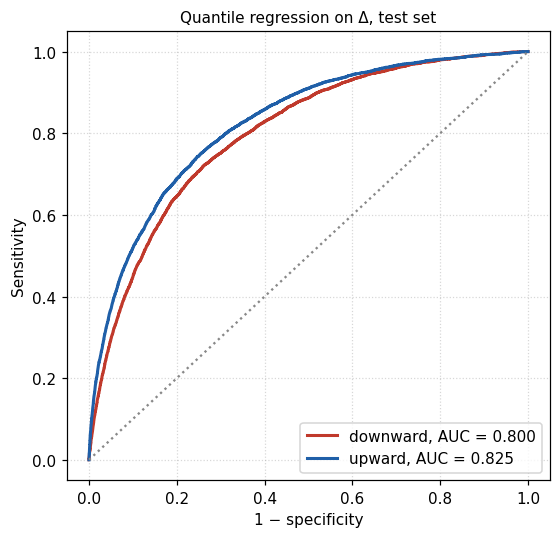

In [8]:
def regressor(direcao):
    return XGBRegressor(**HP[direcao], objective='reg:quantileerror', quantile_alpha=Q[direcao], n_jobs=8, tree_method='hist')


MODELOS, P_TESTE_MEM, TESTE = {}, {}, {}
for d in DIRS:
    t0 = time.time()
    MODELOS[d] = regressor(d).fit(DEV_A[FEATS].values, DEV_A['delta'].values)
    P_TESTE_MEM[d] = SINAL[d] * MODELOS[d].predict(HOLD_A[FEATS].values)
    p_grade = np.full(len(hold), np.nan)
    p_grade[hold.delta.notna().values] = P_TESTE_MEM[d]
    pd.DataFrame({'session_id': hold.session_id.values, 'bloco_id': hold.bloco_id.values,
                  'y': hold[f'y_{d}'].fillna(0).values.astype(int), 'p': p_grade}
                 ).to_csv(f"{SAIDA}/previsoes_teste_{d}.csv.gz", index=False, compression='gzip')
    TESTE[d] = pd.read_csv(f"{SAIDA}/previsoes_teste_{d}.csv.gz")
    print(f"{d}: treino {time.time() - t0:.0f} s | {TESTE[d].p.notna().sum()} blocos de teste com score")

AUC = {d: roc_auc_score(TESTE[d].y[TESTE[d].p.notna()], TESTE[d].p.dropna()) for d in DIRS}
for d in DIRS:
    confere(f"AUC no teste, {d}", AUC[d], JSON_HP[d]['holdout'], tol=1e-6)
confere("AUC no teste, descida (texto da tese)", round(AUC['descida'], 3), 0.800)
confere("AUC no teste, subida (texto da tese)", round(AUC['subida'], 3), 0.825)

fig, ax = plt.subplots(figsize=(5.2, 5))
for d, cor, nome in (("descida", VERM, "downward"), ("subida", AZUL, "upward")):
    t = TESTE[d].dropna(subset=['p'])
    fpr, tpr, _ = roc_curve(t.y, t.p)
    ax.plot(fpr, tpr, color=cor, lw=2, label=f"{nome}, AUC = {AUC[d]:.3f}")
ax.plot([0, 1], [0, 1], ":", color=CINZA)
ax.set_xlabel("1 − specificity"); ax.set_ylabel("Sensitivity"); ax.legend(loc="lower right")
ax.set_title("Quantile regression on Δ, test set", fontsize=10)
fig.tight_layout(); fig.savefig(f"{SAIDA}/roc.png", dpi=200); plt.show()

## 6. Validação cruzada no conjunto de desenvolvimento

As previsões **fora da dobra** (cada bloco previsto por um modelo que não viu o seu doente) são a base de todas as escolhas do passo 8. O conjunto de teste só é usado para medir, uma vez, a escolha já feita. O AUC destas previsões é o AUC de validação cruzada com as 43 características que a tese dá no Apêndice B.

In [9]:
OOF = {}
for d in DIRS:
    t0 = time.time()
    X, y_reg = DEV_A[FEATS].values, DEV_A['delta'].values
    oof = np.zeros(len(X))
    for tr, va in GroupKFold(n_splits=3).split(X, DEV_A[f'y_{d}'].values, DEV_A['subject_id'].values):
        oof[va] = SINAL[d] * regressor(d).fit(X[tr], y_reg[tr]).predict(X[va])
    OOF[d] = oof
    print(f"{d}: {time.time() - t0:.0f} s")
for d in DIRS:
    confere(f"AUC de validação cruzada, {d} (Apêndice B)", roc_auc_score(DEV_A[f'y_{d}'], OOF[d]), JSON_HP[d]['best_cv'], tol=1e-6)

descida: 148 s


subida: 81 s


  ok  AUC de validação cruzada, descida (Apêndice B): 0.8127631174625567


  ok  AUC de validação cruzada, subida (Apêndice B): 0.8329251815197061


## 7. Alarmes, episódios e custo

O alarme é uma **corrida** de blocos com score acima do limiar, e um episódio é uma corrida de blocos-evento. Duas corridas separadas por até 1 minuto contam como uma só, e um alarme deteta um episódio se lhe tocar, aceitando até 2 minutos de antecipação. A sensibilidade é **por episódio**, e o custo mede-se em **minutos de falso alarme por hora**. Como a grade tem linhas vazias, o tempo conta-se só nos blocos com score, e as corridas correm em tempo real porque uma linha vazia ocupa o seu lugar de 15 s.

In [10]:
def runs(mask, gap=GAP_MERGE):
    # início e fim de cada corrida de True, fundindo corridas separadas por até `gap` blocos
    idx = np.where(mask)[0]
    if len(idx) == 0:
        return []
    cortes = np.where(np.diff(idx) > gap + 1)[0]
    return [(g[0], g[-1]) for g in np.split(idx, cortes + 1)]

## 8. Ponto de operação conjunto das duas direções

Os dois detetores correm ao mesmo tempo no mesmo doente, que sente a **união** dos alarmes. Por isso os dois limiares escolhem-se em conjunto. A sensibilidade de cada direção vem do seu próprio alarme, e a carga vem da união.

Varrem-se 18 limiares por direção (entre os percentis 2 e 98 do score no desenvolvimento). No desenvolvimento escolhe-se o par que maximiza a **pior das duas sensibilidades** com a união até 10 minutos de falso alarme por hora e ciclo de serviço até 30 %, e esse par mede-se uma vez no conjunto de teste. Não há limite de duração do alarme, porque o servidor não o aplica.

Para a varredura ser rápida, as sessões concatenam-se numa só série com separadores. Nos scores o separador é vazio, por isso nunca dá alarme. As horas e o ciclo de serviço dividem-se pelos blocos reais (os que têm score), sem contar os separadores.

324 pares de limiares em cada conjunto | 14 s


,alvo_uniao,tau_d,tau_s,sens_d,sens_s,u_FA_h,u_FA_min_h,u_duty,alarmes_h,falsos_alarmes_h,vpp_uniao
0,6,12.98,11.81,0.5246,0.5859,5.76,6.43,0.1874,7.909,5.756,0.272
1,8,12.16,11.81,0.5893,0.5859,6.18,7.35,0.2121,8.411,6.175,0.266
2,10,11.34,10.92,0.6682,0.6572,7.04,9.46,0.2711,9.417,7.037,0.253
3,12,10.51,10.92,0.7388,0.6572,7.53,10.86,0.3118,9.957,7.526,0.244
4,14,10.51,10.92,0.7388,0.6572,7.53,10.86,0.3118,9.957,7.526,0.244


  ok  ponto de operação: limiar da descida (mmHg): 11.34
  ok  ponto de operação: limiar da subida (mmHg): 10.92
  ok  ponto de operação: sens_d: 0.6682
  ok  ponto de operação: sens_s: 0.6572
  ok  ponto de operação: u_FA_min_h: 9.46
  ok  ponto de operação: u_duty: 0.2711
  ok  ponto de operação: alarmes_h: 9.417
  ok  ponto de operação: falsos_alarmes_h: 7.037
  ok  ponto de operação: vpp_uniao: 0.253


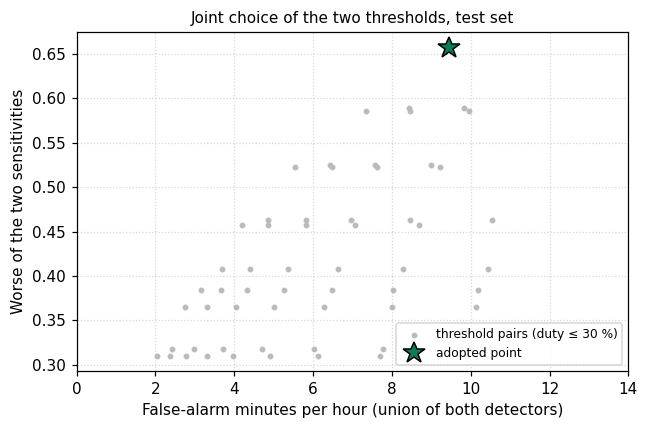

In [11]:
SEP = max(GAP_MERGE, PRE_CREDITO) + 2
ALVOS_UNIAO = [6, 8, 10, 12, 14]


def runs_np(mask):
    idx = np.flatnonzero(mask)
    if idx.size == 0:
        return np.empty((0, 2), int)
    cortes = np.flatnonzero(np.diff(idx) > GAP_MERGE + 1)
    return np.column_stack([np.r_[idx[0], idx[cortes + 1]], np.r_[idx[cortes], idx[-1]]])


def detecta(al, ev):
    if al.size == 0 or ev.size == 0:
        return 0
    return sum(int(np.any((al[:, 1] >= e0 - PRE_CREDITO) & (al[:, 0] <= e1))) for e0, e1 in ev)


def mascara_eventos(ev, n):
    m = np.zeros(n, bool)
    for e0, e1 in ev:
        m[max(0, e0 - PRE_CREDITO):e1 + 1] = True
    return np.concatenate([[0], np.cumsum(m)])


def falsos(al, cs_ev):
    if al.size == 0:
        return 0, 0
    f = ~((cs_ev[al[:, 1] + 1] - cs_ev[al[:, 0]]) > 0)
    return int(f.sum()), int((al[f, 1] - al[f, 0] + 1).sum())


def concatenar(df, cols):
    saida = {c: [] for c in cols}
    for _, g in df.groupby('session_id', sort=False):
        g = g.sort_values('bloco_id')
        for c in cols:
            saida[c].append(g[c].values)
            saida[c].append(np.full(SEP, np.nan) if c.startswith('p_') else np.zeros(SEP, dtype=g[c].values.dtype))
    return {c: np.concatenate(v) for c, v in saida.items()}


def preencher(m, al):
    for a0, a1 in al:
        m[a0:a1 + 1] = True
    return m


def varrer(dados, taus):
    n = len(dados['p_descida'])
    n_real = int(np.isfinite(dados['p_descida']).sum())
    M = {}
    for d in DIRS:
        for tau in taus[d]:
            al = runs_np(dados[f'p_{d}'] >= tau)
            M[(d, round(float(tau), 2))] = (al, preencher(np.zeros(n, bool), al))
    ev = {d: runs_np(dados[f'y_{d}'].astype(bool)) for d in DIRS}
    cs_any = mascara_eventos(runs_np(dados['y_descida'].astype(bool) | dados['y_subida'].astype(bool)), n)
    det = {k: detecta(v[0], ev[k[0]]) for k, v in M.items()}
    horas = n_real * BLOCO_SEG / 3600.0
    linhas = []
    for kd in [k for k in M if k[0] == 'descida']:
        for ks in [k for k in M if k[0] == 'subida']:
            m = M[kd][1] | M[ks][1]
            fa_n, fa_b = falsos(runs_np(m), cs_any)
            linhas.append(dict(tau_d=kd[1], tau_s=ks[1], sens_d=det[kd] / max(len(ev['descida']), 1),
                               sens_s=det[ks] / max(len(ev['subida']), 1), u_FA_h=fa_n / horas,
                               u_FA_min_h=fa_b * BLOCO_SEG / 60.0 / horas, u_duty=m.sum() / n_real))
    return pd.DataFrame(linhas), M, ev, cs_any, n_real


def carga_uniao(dados, M, cs_any, n_real, tau_d, tau_s):
    # alarmes por hora, falsos alarmes por hora e valor preditivo positivo da união, no par escolhido
    n = len(dados['p_descida'])
    al = runs_np(M[('descida', round(float(tau_d), 2))][1] | M[('subida', round(float(tau_s), 2))][1])
    fa_n, _ = falsos(al, cs_any)
    horas = n_real * BLOCO_SEG / 3600.0
    return dict(alarmes_h=len(al) / horas, falsos_alarmes_h=fa_n / horas, vpp_uniao=1 - fa_n / max(len(al), 1))


# scores na grade completa (vazios nas linhas sem alvo) e rótulos a 0 onde não há alvo
for d in DIRS:
    for x, P in ((dev, OOF[d]), (hold, P_TESTE_MEM[d])):
        p = np.full(len(x), np.nan)
        p[x.delta.notna().values] = P
        x[f'p_{d}'] = p
        x[f'y_{d}'] = x[f'y_{d}'].fillna(0)
cols = ['p_descida', 'p_subida', 'y_descida', 'y_subida']
cat_dev, cat_hold = concatenar(dev, cols), concatenar(hold, cols)
TAUS_C = {d: np.round(np.linspace(*np.nanpercentile(dev[f'p_{d}'], [2, 98]), 18), 2) for d in DIRS}
t0 = time.time()
grelha_dev, *_ = varrer(cat_dev, TAUS_C)
grelha_teste, M_TESTE, EV_TESTE, CS_TESTE, N_REAL_TESTE = varrer(cat_hold, TAUS_C)
print(f"{len(grelha_dev)} pares de limiares em cada conjunto | {time.time() - t0:.0f} s")

escolhas = []
for alvo in ALVOS_UNIAO:
    c = grelha_dev[(grelha_dev.u_FA_min_h <= alvo) & (grelha_dev.u_duty <= DUTY_MAX)]
    if not len(c):
        continue
    e = c.loc[np.minimum(c.sens_d, c.sens_s).idxmax()]
    h = grelha_teste[(grelha_teste.tau_d == e.tau_d) & (grelha_teste.tau_s == e.tau_s)].iloc[0]
    escolhas.append(dict(alvo_uniao=alvo, tau_d=e.tau_d, tau_s=e.tau_s, sens_d=round(h.sens_d, 4),
                         sens_s=round(h.sens_s, 4), u_FA_h=round(h.u_FA_h, 2), u_FA_min_h=round(h.u_FA_min_h, 2),
                         u_duty=round(h.u_duty, 4),
                         **{k: round(v, 3) for k, v in carga_uniao(cat_hold, M_TESTE, CS_TESTE, N_REAL_TESTE, e.tau_d, e.tau_s).items()}))
escolhas = pd.DataFrame(escolhas)
display(escolhas)

op = escolhas[escolhas.alvo_uniao == 10].iloc[0]
LIMIAR = {'descida': float(op.tau_d), 'subida': float(op.tau_s)}
ref = pd.read_csv(f"{REF}/ponto_tempo_reafinado_cargas.csv")
ref = ref[(ref.variante == 'tudo') & (ref.alvo == 10)].iloc[0]
confere("ponto de operação: limiar da descida (mmHg)", float(op.tau_d), float(ref.tau_d), tol=1e-9)
confere("ponto de operação: limiar da subida (mmHg)", float(op.tau_s), float(ref.tau_s), tol=1e-9)
for k, kr, tol in (('sens_d', 'sens_d', 5e-4), ('sens_s', 'sens_s', 5e-4), ('u_FA_min_h', 'min_falso_h', 5e-2),
                   ('u_duty', 'ciclo_servico', 5e-4), ('alarmes_h', 'alarmes_h', 5e-2),
                   ('falsos_alarmes_h', 'falsos_alarmes_h', 5e-2), ('vpp_uniao', 'vpp_uniao', 5e-4)):
    confere(f"ponto de operação: {k}", float(op[k]), float(ref[kr]), tol=tol)

fig, ax = plt.subplots(figsize=(6, 4))
s = grelha_teste[grelha_teste.u_duty <= DUTY_MAX]
ax.scatter(s.u_FA_min_h, np.minimum(s.sens_d, s.sens_s), s=8, color="#bbbbbb", label="threshold pairs (duty ≤ 30 %)")
ax.plot(op.u_FA_min_h, min(op.sens_d, op.sens_s), "*", ms=15, color="#0a7d54", mec="k", label="adopted point")
ax.set_xlabel("False-alarm minutes per hour (union of both detectors)")
ax.set_ylabel("Worse of the two sensitivities")
ax.set_xlim(0, 14); ax.legend(loc="lower right", fontsize=8)
ax.set_title("Joint choice of the two thresholds, test set", fontsize=10)
fig.tight_layout(); fig.savefig(f"{SAIDA}/conjunta.png", dpi=200); plt.show()

## 9. Métricas por episódio no ponto de operação

No ponto de operação adotado (limiar do passo 8), no conjunto de teste:

* sensibilidade por episódio, valor preditivo positivo (fração de alarmes que tocam um episódio), ciclo de serviço e alarmes por hora de cada detetor;
* comparação com um alarme aleatório com a mesma estrutura (o mesmo número e duração de alarmes, em posições sorteadas na sessão, 2000 repetições);
* valor preditivo positivo a seis níveis de sensibilidade;
* concentração da carga de falso alarme por sessão;
* episódios falhados, a sua duração mediana e o pico do score dentro deles.

A sensibilidade, o valor preditivo positivo e os alarmes por hora de cada detetor são comparados com o ficheiro da tese. Os outros números são calculados só aqui.

In [12]:
SENS_ALVO = [0.80, 0.60, 0.50, 0.30, 0.10, 0.04]
RNG = np.random.default_rng(42)


def sessoes(df):
    # por sessão: rótulo, score (vazio nas linhas sem alvo) e máscara dos blocos com score
    return [(g.y.values.astype(bool), g.p.values, np.isfinite(g.p.values)) for _, g in df.groupby('session_id', sort=False)]


def medir(grupos, tau):
    det = n_ev = n_al = n_true = blocos = tot = 0
    fa_min = 0.0
    for y, p, ok in grupos:
        tot += int(ok.sum())
        ev = runs(y)
        n_ev += len(ev)
        al = runs((p >= tau) & ok)
        n_al += len(al)
        for (a0, a1) in al:
            blocos += (a1 - a0 + 1)
            if any(a1 >= (e0 - PRE_CREDITO) and a0 <= e1 for (e0, e1) in ev):
                n_true += 1
            else:
                fa_min += (a1 - a0 + 1) * BLOCO_SEG / 60.0
        det += sum(any(a1 >= (e0 - PRE_CREDITO) and a0 <= e1 for (a0, a1) in al) for (e0, e1) in ev)
    horas = tot * BLOCO_SEG / 3600.0
    return dict(det=det, n_ev=n_ev, n_al=n_al, n_true=n_true, sens=det / max(n_ev, 1), vpp=n_true / max(n_al, 1),
                duty=blocos / tot, alarmes_h=n_al / horas, fa_min_h=fa_min / horas, horas=horas)


def tau_para_sens(grupos, alvo, lo, hi):
    for _ in range(40):
        m = (lo + hi) / 2
        if medir(grupos, m)['sens'] >= alvo:
            lo = m
        else:
            hi = m
    return lo


def aleatorio_igual_estrutura(grupos, tau, n_rep=2000):
    sens = []
    for _ in range(n_rep):
        det = n_ev = 0
        for y, p, ok in grupos:
            ev = runs(y)
            n_ev += len(ev)
            novos = []
            for (a0, a1) in runs((p >= tau) & ok):
                dur = a1 - a0 + 1
                if dur >= len(y):
                    novos.append((0, len(y) - 1)); continue
                ini = RNG.integers(0, len(y) - dur + 1)
                novos.append((ini, ini + dur - 1))
            det += sum(any(a1 >= (e0 - PRE_CREDITO) and a0 <= e1 for (a0, a1) in novos) for (e0, e1) in ev)
        sens.append(det / max(n_ev, 1))
    return np.array(sens)


NUMEROS = {}
for d in DIRS:
    t0 = time.time()
    tau_op = LIMIAR[d]
    t = TESTE[d]
    g = sessoes(t)
    ponto = medir(g, tau_op)
    alea = aleatorio_igual_estrutura(g, tau_op)
    vpp = []
    for s in SENS_ALVO:
        m = medir(g, tau_para_sens(g, s, t.p.min(), t.p.max()))
        vpp.append([s, round(m['vpp'], 4), m['n_true'], m['n_al']])
    carga = []
    for _, gs in t.groupby('session_id', sort=False):
        p, ev = gs.p.values, runs(gs.y.values.astype(bool))
        carga.append(sum((a1 - a0 + 1) * BLOCO_SEG / 60.0 for (a0, a1) in runs(p >= tau_op)
                         if not any(a1 >= (e0 - PRE_CREDITO) and a0 <= e1 for (e0, e1) in ev)))
    carga = np.sort(np.array(carga))[::-1]
    falh_dur, det_dur, falh_pico, det_pico = [], [], [], []
    for y, p, ok in g:
        al = runs((p >= tau_op) & ok)
        for (e0, e1) in runs(y):
            dur, pico = (e1 - e0 + 1) * BLOCO_SEG / 60.0, float(np.nanmax(p[e0:e1 + 1]))
            if any(a1 >= (e0 - PRE_CREDITO) and a0 <= e1 for (a0, a1) in al):
                det_dur.append(dur); det_pico.append(pico)
            else:
                falh_dur.append(dur); falh_pico.append(pico)
    NUMEROS[d] = dict(
        op_sens=round(ponto['sens'], 4), op_vpp=round(ponto['vpp'], 4), op_true=ponto['n_true'], op_al=ponto['n_al'],
        op_duty=round(ponto['duty'], 4), op_alarmes_h=round(ponto['alarmes_h'], 1),
        aleat_sens=round(float(alea.mean()), 3), aleat_lo=round(float(np.percentile(alea, 2.5)), 3),
        aleat_hi=round(float(np.percentile(alea, 97.5)), 3), ganho_nulo=round(ponto['sens'] - float(alea.mean()), 3),
        vpp=vpp, carga_top10=round(float(carga[:max(1, len(carga) // 10)].sum() / max(carga.sum(), 1e-9)), 3),
        carga_zero=round(float((carga == 0).mean()), 3), falhados=len(falh_dur), episodios=len(falh_dur) + len(det_dur),
        dur_falh=round(float(np.median(falh_dur)), 2), dur_det=round(float(np.median(det_dur)), 2),
        pico_falh=round(float(np.median(falh_pico)), 1), pico_det=round(float(np.median(det_pico)), 1))
    print(f"{d}: {time.time() - t0:.0f} s")

display(pd.DataFrame({d: {k: v for k, v in NUMEROS[d].items() if k != 'vpp'} for d in DIRS}))
display(pd.DataFrame({d: {f"VPP a sens. {s:.0%}": f"{v:.1%}  ({a} alarmes)" for s, v, _, a in NUMEROS[d]['vpp']} for d in DIRS}))
for d, suf in (('descida', 'd'), ('subida', 's')):
    confere(f"{d}: sensibilidade por episódio", NUMEROS[d]['op_sens'], float(ref[f'sens_{suf}']), tol=5e-4)
    confere(f"{d}: valor preditivo positivo", NUMEROS[d]['op_vpp'], float(ref[f'vpp_{"descida" if suf == "d" else "subida"}']), tol=5e-4)
    confere(f"{d}: alarmes por hora", NUMEROS[d]['op_alarmes_h'], float(ref[f'alarmes_h_{"descida" if suf == "d" else "subida"}']), tol=5e-2)

descida: 96 s


subida: 89 s


,descida,subida
op_sens,0.6682,0.6572
op_vpp,0.1749,0.1670
op_true,937.0000,849.0000
op_al,5357.0000,5084.0000
op_duty,0.1460,0.1496
op_alarmes_h,6.9000,6.6000
aleat_sens,0.3590,0.3450
aleat_lo,0.3360,0.3220
aleat_hi,0.3820,0.3700
ganho_nulo,0.3100,0.3120


,descida,subida
VPP a sens. 80%,15.5% (7049 alarmes),14.0% (7255 alarmes)
VPP a sens. 60%,18.7% (4562 alarmes),18.0% (4375 alarmes)
VPP a sens. 50%,21.6% (3336 alarmes),19.5% (3333 alarmes)
VPP a sens. 30%,26.0% (1657 alarmes),27.7% (1443 alarmes)
VPP a sens. 10%,34.4% (404 alarmes),40.4% (329 alarmes)
VPP a sens. 4%,39.3% (140 alarmes),50.4% (113 alarmes)


  ok  descida: sensibilidade por episódio: 0.6682
  ok  descida: valor preditivo positivo: 0.1749
  ok  descida: alarmes por hora: 6.9
  ok  subida: sensibilidade por episódio: 0.6572
  ok  subida: valor preditivo positivo: 0.167
  ok  subida: alarmes por hora: 6.6


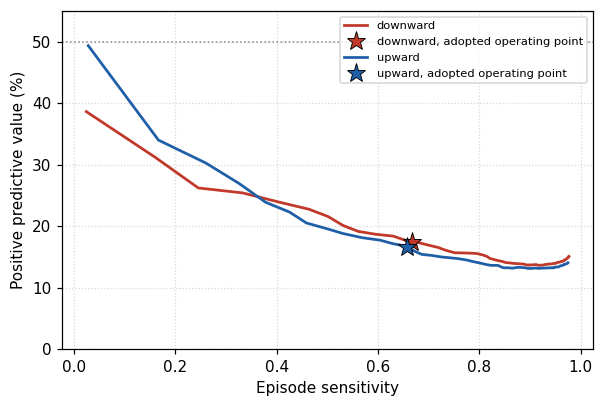

In [13]:
fig, ax = plt.subplots(figsize=(5.6, 3.8))
for d, cor, nome in (("descida", VERM, "downward"), ("subida", AZUL, "upward")):
    t = TESTE[d]
    g = sessoes(t)
    pts = [medir(g, tau) for tau in np.nanquantile(t.p, np.linspace(0.50, 0.999, 60))]
    ax.plot([m['sens'] for m in pts], [100 * m['vpp'] for m in pts], color=cor, lw=1.8, label=nome)
    pm = medir(g, LIMIAR[d])
    ax.plot(pm['sens'], 100 * pm['vpp'], "*", color=cor, ms=13, mec="k", mew=0.6, label=f"{nome}, adopted operating point")
ax.axhline(50, color=CINZA, ls=":", lw=1)
ax.set_xlabel("Episode sensitivity"); ax.set_ylabel("Positive predictive value (%)"); ax.set_ylim(0, 55)
ax.legend(loc="upper right", fontsize=7.5)
fig.tight_layout(); fig.savefig(f"{SAIDA}/vpp_sensibilidade.png", dpi=200); plt.show()

## 10. Exportação do modelo e comparação com o servidor

O ficheiro que o servidor carrega (`modelo_tendencia_ppg_quant.joblib`) tem, por direção, o modelo, a lista das 43 características pela ordem do treino, o sinal do score e o limiar. Aqui exporta-se o modelo treinado no passo 5 com o ponto de operação do passo 8, e compara-se com o que está instalado no servidor, com as mesmas previsões no conjunto de teste.

No fim mostra-se a importância de cada característica (ganho total do XGBoost, normalizado para somar 1).

In [14]:
import datetime
e10 = escolhas[escolhas.alvo_uniao == 10].iloc[0]
pacote = {"meta": {"variante": "ppg_quant_tempo, 43 caracteristicas, ancoras CAUSAIS por SESSAO, janela de 5 min por tempo exato",
                   "treinado_em": datetime.datetime.now().strftime("%Y-%m-%d %H:%M"), "n_blocos_dev": int(len(DEV_A)),
                   "teste_sens_descida": float(e10.sens_d), "teste_sens_subida": float(e10.sens_s),
                   "teste_uniao_FA_min_h": float(e10.u_FA_min_h), "teste_uniao_duty": float(e10.u_duty),
                   "teste_vpp_uniao": float(e10.vpp_uniao)}}
for d in DIRS:
    pacote[d] = {"booster": MODELOS[d].get_booster().save_raw(), "feats": FEATS, "sinal": SINAL[d], "limiar": LIMIAR[d],
                 "limite_min": None, "portao_blocos": 4, "portao_limite": 1e9}   # o servidor lê os dois campos do portão; 1e9 deixa-o sempre aberto
joblib.dump(pacote, f"{SAIDA}/modelo_tendencia_ppg_quant.joblib")

servidor = joblib.load(SERVIDOR)
X_teste = HOLD_A[FEATS].values
for d in DIRS:
    for k in ("feats", "sinal", "limiar"):
        confere(f"servidor, {d}: {k}", pacote[d][k], servidor[d][k])
    b = xgb.Booster(); b.load_model(bytearray(servidor[d]["booster"]))
    p_servidor = SINAL[d] * b.predict(xgb.DMatrix(X_teste))
    confere(f"servidor, {d}: diferença máxima das previsões no teste", float(np.abs(p_servidor - P_TESTE_MEM[d]).max()),
            0.0, tol=1e-5)

  ok  servidor, descida: feats: 43 elementos, iguais
  ok  servidor, descida: sinal: -1.0
  ok  servidor, descida: limiar: 11.34
  ok  servidor, descida: diferença máxima das previsões no teste: 0.0
  ok  servidor, subida: feats: 43 elementos, iguais
  ok  servidor, subida: sinal: 1.0
  ok  servidor, subida: limiar: 10.92


  ok  servidor, subida: diferença máxima das previsões no teste: 0.0


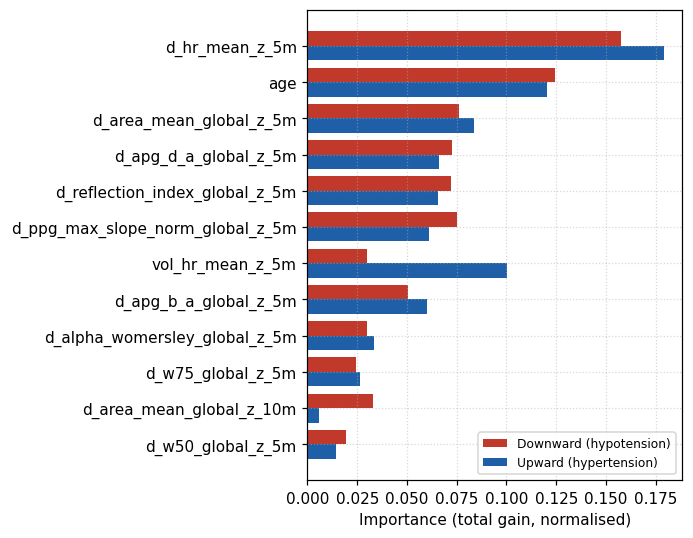

In [15]:
IMP = {}
for d in DIRS:
    g = MODELOS[d].get_booster().get_score(importance_type='total_gain')
    s = pd.Series({f: g.get(f, g.get(f"f{i}", 0.0)) for i, f in enumerate(FEATS)}, dtype=float)
    IMP[d] = (s / s.sum()).sort_values(ascending=False)

top = (IMP['descida'] + IMP['subida']).sort_values(ascending=False).index[:12][::-1]
fig, ax = plt.subplots(figsize=(6.4, 5))
y = np.arange(len(top))
ax.barh(y + 0.2, IMP['descida'][top], 0.4, color=VERM, label="Downward (hypotension)")
ax.barh(y - 0.2, IMP['subida'][top], 0.4, color=AZUL, label="Upward (hypertension)")
ax.set_yticks(y); ax.set_yticklabels(top); ax.set_xlabel("Importance (total gain, normalised)")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout(); fig.savefig(f"{SAIDA}/importancia.png", dpi=200); plt.show()

## Resumo das verificações

In [16]:
v = pd.DataFrame(VERIFICACOES, columns=["verificação", "obtido", "na tese", "igual"])
print(f"{int(v.igual.sum())} de {len(v)} verificações iguais aos resultados da tese")
display(v)

47 de 47 verificações iguais aos resultados da tese


,verificação,obtido,na tese,igual
0,versão do XGBoost (a dos resultados da tese),3.3.0,3.3.0,True
1,versão do scikit-learn (a dos resultados da tese),1.9.1,1.9.1,True
2,demonstração: mesmas janelas aceites,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...","[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...",True
3,demonstração: mesmas colunas (inclui as de mor...,"[age, alpha_womersley, alpha_womersley_b, apg_...","[age, alpha_womersley, alpha_womersley_b, apg_...",True
4,demonstração: diferença máxima nas característ...,0.0,0.0,True
5,dev: mesmo número de blocos,1308182,1308182,True
6,dev: mesmas sessões e blocos,True,True,True
7,dev: valores em falta nos mesmos sítios,True,True,True
8,dev: diferença máxima nos valores,0.0,0.0,True
9,holdout: mesmo número de blocos,224609,224609,True


## 11. O que fica fora deste notebook

Este notebook segue o caminho do modelo adotado. As análises à volta dele estão em scripts próprios, que a tabela seguinte indica.

| Análise | Onde está | Na tese |
|---|---|---|
| Extração das características novas | `3_tendencia_modelo_final/extracao_morfologia/` | Cap. 6 e Anexo A |
| Tabela com a janela por tempo e os hiperparâmetros | `3_tendencia_modelo_final/tendencia_tempo_fixo/` (`construir_tabela_ppg_morf.py`, `tempo_fixo.py`, `01_optuna_tempo.py`) | Cap. 6 |
| Classificador binário e comparação com a regressão quantílica | notebook `02_tendencia_classificador.ipynb` e `3_tendencia_modelo_final/tendencia_tempo_fixo/02_classificador_vs_quantilica.py` | Cap. 6 e Anexo E |
| Escolha da janela, do quantil e persistência só com o desenvolvimento | `3_tendencia_modelo_final/janela_desenvolvimento/` | Cap. 6 |
| Quanto vale o ECG | `3_tendencia_modelo_final/ablacao_ecg_tempo/` | Cap. 6 |
| Redes e híbridos (BiLSTM, BiTCN) | `3_tendencia_modelo_final/tendencia_tempo_fixo/hibridos/` | Cap. 6 e anexos |
| Submodelos de alarmes e de estável, e um só doente | `4_tendencia_selecao_e_experiencias/submodelos_do_alarme_e_do_estavel/`, `4_tendencia_selecao_e_experiencias/modelos_de_um_so_doente/` | Anexos |
| Detetor em tempo real no servidor e equivalência com o treino | `3_tendencia_modelo_final/servidor_tempo/` (`verificar_servidor_tempo.py`, `ensaio_worker_tempo.py`) | Cap. 4 e Cap. 7 |